# U.S. Airline Operational Performance Analytics 2025
## 02 — Exploratory Data Analysis (EDA)


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print(f"Pandas version: {pd.__version__}")
print("Libraries imported successfully.")


Matplotlib is building the font cache; this may take a moment.


Pandas version: 3.0.3
Libraries imported successfully.


## 2. Detect Project Folder

In [2]:
current_path = Path.cwd().resolve()

if (current_path / "data" / "processed").exists():
    project_root = current_path
elif (current_path.parent / "data" / "processed").exists():
    project_root = current_path.parent
else:
    raise FileNotFoundError("Folder data/processed tidak ditemukan.")

processed_path = project_root / "data" / "processed"
analysis_path = project_root / "data" / "analysis"
analysis_path.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")
print(f"Processed path: {processed_path}")
print(f"Analysis path: {analysis_path}")


Project root: C:\Bootcamp Dibimbing\Assignment\D30_Portfolio
Processed path: C:\Bootcamp Dibimbing\Assignment\D30_Portfolio\data\processed
Analysis path: C:\Bootcamp Dibimbing\Assignment\D30_Portfolio\data\analysis


## 3. Validate Processed Files

In [3]:
processed_files = sorted(processed_path.glob("airline_2025_*_processed.csv.gz"))

print(f"Total processed files: {len(processed_files)}")

if len(processed_files) != 12:
    raise ValueError(f"Expected 12 processed files, found {len(processed_files)}.")

for file in processed_files:
    print(file.name)


Total processed files: 12
airline_2025_01_processed.csv.gz
airline_2025_02_processed.csv.gz
airline_2025_03_processed.csv.gz
airline_2025_04_processed.csv.gz
airline_2025_05_processed.csv.gz
airline_2025_06_processed.csv.gz
airline_2025_07_processed.csv.gz
airline_2025_08_processed.csv.gz
airline_2025_09_processed.csv.gz
airline_2025_10_processed.csv.gz
airline_2025_11_processed.csv.gz
airline_2025_12_processed.csv.gz


## 4. Monthly Performance

In [4]:
audit_df = pd.read_csv(processed_path / "preprocessing_audit_2025.csv")

monthly_df = audit_df.copy()
monthly_df["OnTimeArrivalRatePct"] = 100 - monthly_df["ArrivalDelayRatePct"]
monthly_df["MonthName"] = pd.to_datetime(
    monthly_df["Month"], format="%m"
).dt.month_name()

display(
    monthly_df[
        [
            "MonthName",
            "RowsSaved",
            "ArrivalDelayRatePct",
            "OnTimeArrivalRatePct",
            "CancellationRatePct",
            "DiversionRatePct",
            "SevereDelayRatePct"
        ]
    ]
)

worst_month = monthly_df.loc[monthly_df["ArrivalDelayRatePct"].idxmax()]
best_month = monthly_df.loc[monthly_df["ArrivalDelayRatePct"].idxmin()]

print(f"Highest delay rate month: {worst_month['MonthName']} ({worst_month['ArrivalDelayRatePct']:.2f}%)")
print(f"Lowest delay rate month: {best_month['MonthName']} ({best_month['ArrivalDelayRatePct']:.2f}%)")


,MonthName,RowsSaved,ArrivalDelayRatePct,OnTimeArrivalRatePct,CancellationRatePct,DiversionRatePct,SevereDelayRatePct
0,January,539747,18.789168,81.210832,3.022157,0.216027,6.365494
1,February,504884,20.766764,79.233236,1.466674,0.198659,7.427147
2,March,600872,19.590377,80.409623,1.152159,0.274268,7.073262
3,April,583950,19.663857,80.336143,0.841510,0.223649,6.750731
4,May,605648,23.601763,76.398237,1.047473,0.285644,8.725614
5,June,611575,28.259035,71.740965,1.591955,0.387033,11.317459
6,July,631428,28.885252,71.114748,2.450477,0.497919,12.083824
7,August,602378,22.555593,77.444407,1.076235,0.358911,8.222214
8,September,562439,16.631622,83.368378,0.513122,0.217624,5.421723
9,October,605844,20.321991,79.678009,0.528849,0.176613,6.328108


Highest delay rate month: July (28.89%)
Lowest delay rate month: September (16.63%)


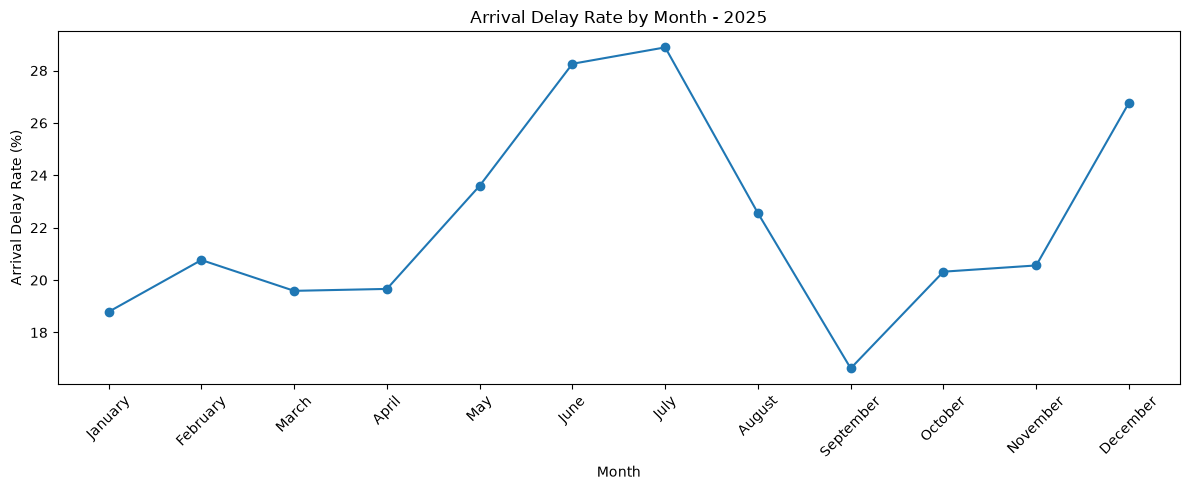

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_df["MonthName"], monthly_df["ArrivalDelayRatePct"], marker="o")
plt.title("Arrival Delay Rate by Month - 2025")
plt.xlabel("Month")
plt.ylabel("Arrival Delay Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Aggregate 12 Months

In [6]:
analysis_columns = [
    "Reporting_Airline",
    "Origin",
    "Dest",
    "Route",
    "DepDel15",
    "ArrDelay",
    "ArrivalDelayed15Flag",
    "ValidArrivalFlag",
    "SevereDelayFlag",
    "Cancelled",
    "Diverted",
    "ScheduledDepHour",
    "DeparturePeriod",
    "DayName",
    "WeekendFlag",
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

airline_parts = []
origin_parts = []
destination_parts = []
route_parts = []
hour_parts = []
period_parts = []
day_parts = []
weekend_parts = []
cause_parts = []

for file_number, file in enumerate(processed_files, start=1):
    print(f"Reading file {file_number}/12: {file.name}")

    df = pd.read_csv(
        file,
        usecols=analysis_columns,
        compression="gzip",
        low_memory=False
    )

    df["FlightCount"] = 1
    df["ValidArrivalCount"] = df["ValidArrivalFlag"].fillna(0).astype(int)
    df["Delayed15Count"] = df["ArrivalDelayed15Flag"].fillna(0).astype(int)
    df["SevereDelayCount"] = df["SevereDelayFlag"].fillna(0).astype(int)
    df["CancelledCount"] = (df["Cancelled"] == 1).astype(int)
    df["DivertedCount"] = (df["Diverted"] == 1).astype(int)
    df["ValidDepartureCount"] = (
        df["DepDel15"].notna() & (df["Cancelled"] == 0)
    ).astype(int)
    df["DepartureDelayed15Count"] = (df["DepDel15"] == 1).astype(int)
    df["DelayedArrivalMinutes"] = np.where(
        df["ArrivalDelayed15Flag"] == 1,
        df["ArrDelay"],
        0
    )

    airline_parts.append(
        df.groupby("Reporting_Airline", as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidArrivals=("ValidArrivalCount", "sum"),
            Delayed15Flights=("Delayed15Count", "sum"),
            SevereDelayFlights=("SevereDelayCount", "sum"),
            CancelledFlights=("CancelledCount", "sum"),
            DivertedFlights=("DivertedCount", "sum"),
            DelayedArrivalMinutes=("DelayedArrivalMinutes", "sum")
        )
    )

    origin_parts.append(
        df.groupby("Origin", as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidDepartures=("ValidDepartureCount", "sum"),
            DepartureDelayed15Flights=("DepartureDelayed15Count", "sum"),
            CancelledFlights=("CancelledCount", "sum")
        )
    )

    destination_parts.append(
        df.groupby("Dest", as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidArrivals=("ValidArrivalCount", "sum"),
            Delayed15Flights=("Delayed15Count", "sum"),
            SevereDelayFlights=("SevereDelayCount", "sum")
        )
    )

    route_parts.append(
        df.groupby(["Origin", "Dest", "Route"], as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidArrivals=("ValidArrivalCount", "sum"),
            Delayed15Flights=("Delayed15Count", "sum"),
            SevereDelayFlights=("SevereDelayCount", "sum"),
            DelayedArrivalMinutes=("DelayedArrivalMinutes", "sum")
        )
    )

    hour_parts.append(
        df.groupby("ScheduledDepHour", as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidArrivals=("ValidArrivalCount", "sum"),
            Delayed15Flights=("Delayed15Count", "sum")
        )
    )

    period_parts.append(
        df.groupby("DeparturePeriod", as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidArrivals=("ValidArrivalCount", "sum"),
            Delayed15Flights=("Delayed15Count", "sum")
        )
    )

    day_parts.append(
        df.groupby("DayName", as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidArrivals=("ValidArrivalCount", "sum"),
            Delayed15Flights=("Delayed15Count", "sum")
        )
    )

    weekend_parts.append(
        df.groupby("WeekendFlag", as_index=False).agg(
            TotalFlights=("FlightCount", "sum"),
            ValidArrivals=("ValidArrivalCount", "sum"),
            Delayed15Flights=("Delayed15Count", "sum")
        )
    )

    cause_parts.append(
        pd.DataFrame({
            "DelayCause": [
                "Carrier",
                "Weather",
                "NAS",
                "Security",
                "Late Aircraft"
            ],
            "DelayMinutes": [
                df["CarrierDelay"].fillna(0).sum(),
                df["WeatherDelay"].fillna(0).sum(),
                df["NASDelay"].fillna(0).sum(),
                df["SecurityDelay"].fillna(0).sum(),
                df["LateAircraftDelay"].fillna(0).sum()
            ]
        })
    )

    print(f"Rows analyzed: {len(df):,}")
    del df

print("All 12 months aggregated successfully.")


Reading file 1/12: airline_2025_01_processed.csv.gz
Rows analyzed: 539,747
Reading file 2/12: airline_2025_02_processed.csv.gz
Rows analyzed: 504,884
Reading file 3/12: airline_2025_03_processed.csv.gz
Rows analyzed: 600,872
Reading file 4/12: airline_2025_04_processed.csv.gz
Rows analyzed: 583,950
Reading file 5/12: airline_2025_05_processed.csv.gz
Rows analyzed: 605,648
Reading file 6/12: airline_2025_06_processed.csv.gz
Rows analyzed: 611,575
Reading file 7/12: airline_2025_07_processed.csv.gz
Rows analyzed: 631,428
Reading file 8/12: airline_2025_08_processed.csv.gz
Rows analyzed: 602,378
Reading file 9/12: airline_2025_09_processed.csv.gz
Rows analyzed: 562,439
Reading file 10/12: airline_2025_10_processed.csv.gz
Rows analyzed: 605,844
Reading file 11/12: airline_2025_11_processed.csv.gz
Rows analyzed: 570,550
Reading file 12/12: airline_2025_12_processed.csv.gz
Rows analyzed: 582,304
All 12 months aggregated successfully.


## 6. Airline Performance

In [7]:
airline_df = (
    pd.concat(airline_parts, ignore_index=True)
    .groupby("Reporting_Airline", as_index=False)
    .sum(numeric_only=True)
)

airline_df["ArrivalDelayRatePct"] = (
    airline_df["Delayed15Flights"] / airline_df["ValidArrivals"] * 100
)
airline_df["SevereDelayRatePct"] = (
    airline_df["SevereDelayFlights"] / airline_df["ValidArrivals"] * 100
)
airline_df["CancellationRatePct"] = (
    airline_df["CancelledFlights"] / airline_df["TotalFlights"] * 100
)
airline_df["DiversionRatePct"] = (
    airline_df["DivertedFlights"] / airline_df["TotalFlights"] * 100
)
airline_df["AvgDelayMinutesDelayedFlights"] = (
    airline_df["DelayedArrivalMinutes"] / airline_df["Delayed15Flights"]
)

airline_df = airline_df.sort_values("ArrivalDelayRatePct", ascending=False)

print("Top 5 highest arrival delay rate:")
display(
    airline_df[
        [
            "Reporting_Airline",
            "TotalFlights",
            "ArrivalDelayRatePct",
            "SevereDelayRatePct",
            "CancellationRatePct",
            "AvgDelayMinutesDelayedFlights"
        ]
    ].head(5)
)

print("Top 5 lowest arrival delay rate:")
display(
    airline_df[
        [
            "Reporting_Airline",
            "TotalFlights",
            "ArrivalDelayRatePct",
            "SevereDelayRatePct",
            "CancellationRatePct",
            "AvgDelayMinutesDelayedFlights"
        ]
    ].tail(5).sort_values("ArrivalDelayRatePct")
)


Top 5 highest arrival delay rate:


,Reporting_Airline,TotalFlights,ArrivalDelayRatePct,SevereDelayRatePct,CancellationRatePct,AvgDelayMinutesDelayedFlights
4,F9,198065,27.911551,11.755891,1.771136,84.414782
9,OH,248735,27.529766,12.280613,4.580779,91.059670
2,B6,231413,26.152279,10.956185,1.652889,76.137667
0,AA,973653,25.711425,10.135374,1.815739,83.304557
5,G4,130899,24.965356,9.811998,0.469828,85.393610


Top 5 lowest arrival delay rate:


,Reporting_Airline,TotalFlights,ArrivalDelayRatePct,SevereDelayRatePct,CancellationRatePct,AvgDelayMinutesDelayedFlights
6,HA,80084,17.281150,3.476398,0.824135,53.004230
3,DL,1026332,19.794217,7.239633,1.082885,73.275796
10,OO,839821,20.721714,8.534274,1.410181,83.814540
7,MQ,299322,21.039286,6.917265,2.242735,63.285554
12,WN,1391885,21.395053,6.433950,0.847699,56.978311


## 7. Airport Performance

In [8]:
origin_df = (
    pd.concat(origin_parts, ignore_index=True)
    .groupby("Origin", as_index=False)
    .sum(numeric_only=True)
)

origin_df["DepartureDelayRatePct"] = (
    origin_df["DepartureDelayed15Flights"] / origin_df["ValidDepartures"] * 100
)
origin_df["CancellationRatePct"] = (
    origin_df["CancelledFlights"] / origin_df["TotalFlights"] * 100
)

origin_filtered_df = origin_df[
    origin_df["TotalFlights"] >= 10_000
].sort_values("DepartureDelayRatePct", ascending=False)

print("Top origin airports by departure delay rate (min 10,000 flights):")
display(origin_filtered_df.head(15))


Top origin airports by departure delay rate (min 10,000 flights):


,Origin,TotalFlights,ValidDepartures,DepartureDelayed15Flights,CancelledFlights,DepartureDelayRatePct,CancellationRatePct
301,SFB,10495,10449,3001,46,28.720452,0.438304
90,DFW,315854,307148,87982,8706,28.644823,2.756337
84,DAL,71366,70315,19109,1051,27.176278,1.472690
249,PBI,30785,30308,8003,477,26.405569,1.549456
55,BWI,96100,94808,24383,1292,25.718294,1.344433
86,DCA,142506,137005,35184,5501,25.680815,3.860188
89,DEN,317686,315242,80678,2444,25.592402,0.769313
219,MIA,111907,110488,27939,1419,25.286909,1.268017
242,ORD,327028,321372,80724,5656,25.118554,1.729516
119,FLL,87585,86493,21603,1092,24.976588,1.246789


In [9]:
destination_df = (
    pd.concat(destination_parts, ignore_index=True)
    .groupby("Dest", as_index=False)
    .sum(numeric_only=True)
)

destination_df["ArrivalDelayRatePct"] = (
    destination_df["Delayed15Flights"] / destination_df["ValidArrivals"] * 100
)
destination_df["SevereDelayRatePct"] = (
    destination_df["SevereDelayFlights"] / destination_df["ValidArrivals"] * 100
)

destination_filtered_df = destination_df[
    destination_df["TotalFlights"] >= 10_000
].sort_values("ArrivalDelayRatePct", ascending=False)

print("Top destination airports by arrival delay rate (min 10,000 flights):")
display(destination_filtered_df.head(15))


Top destination airports by arrival delay rate (min 10,000 flights):


,Dest,TotalFlights,ValidArrivals,Delayed15Flights,SevereDelayFlights,ArrivalDelayRatePct,SevereDelayRatePct
301,SFB,10497,10425,3784,1661,36.297362,15.932854
86,DCA,142554,136407,38685,15243,28.359982,11.174646
341,TYS,13265,12970,3667,1504,28.272938,11.595991
249,PBI,30788,30234,8384,3236,27.730370,10.703182
111,EWR,120344,116774,31786,15280,27.220100,13.085105
310,SJU,35712,35323,9451,3242,26.755938,9.178156
53,BUF,20654,20186,5341,1959,26.458932,9.704746
329,SYR,10386,10104,2644,969,26.167854,9.590261
196,LGA,135706,130999,34243,14605,26.139894,11.148940
44,BOS,142850,140277,36616,15727,26.102640,11.211389


## 8. Route Performance

In [10]:
route_df = (
    pd.concat(route_parts, ignore_index=True)
    .groupby(["Origin", "Dest", "Route"], as_index=False)
    .sum(numeric_only=True)
)

route_df["ArrivalDelayRatePct"] = (
    route_df["Delayed15Flights"] / route_df["ValidArrivals"] * 100
)
route_df["SevereDelayRatePct"] = (
    route_df["SevereDelayFlights"] / route_df["ValidArrivals"] * 100
)
route_df["AvgDelayMinutesDelayedFlights"] = (
    route_df["DelayedArrivalMinutes"] / route_df["Delayed15Flights"]
)

route_filtered_df = route_df[
    route_df["TotalFlights"] >= 1_000
].sort_values("ArrivalDelayRatePct", ascending=False)

print("Top routes by arrival delay rate (min 1,000 flights):")
display(route_filtered_df.head(20))


Top routes by arrival delay rate (min 1,000 flights):


,Origin,Dest,Route,TotalFlights,ValidArrivals,Delayed15Flights,SevereDelayFlights,DelayedArrivalMinutes,ArrivalDelayRatePct,SevereDelayRatePct,AvgDelayMinutesDelayedFlights
1541,DCA,HPN,DCA - HPN,1359,1250,494,231,39857.0,39.520000,18.480000,80.682186
1910,DFW,MSN,DFW - MSN,1094,1065,404,177,35109.0,37.934272,16.619718,86.903465
155,ASE,DFW,ASE - DFW,1178,1081,404,208,43801.0,37.372803,19.241443,108.418317
2816,HPN,DCA,HPN - DCA,1359,1267,470,230,49285.0,37.095501,18.153118,104.861702
5131,PHL,SJU,PHL - SJU,1638,1607,592,234,47467.0,36.838830,14.561294,80.180743
1587,DCA,SAV,DCA - SAV,1074,1009,369,189,31336.0,36.570862,18.731417,84.921409
4744,ORD,FSD,ORD - FSD,1685,1639,594,255,48685.0,36.241611,15.558267,81.961279
90,ALB,DCA,ALB - DCA,1263,1173,425,163,40578.0,36.231884,13.895993,95.477647
1940,DFW,SAN,DFW - SAN,3434,3315,1201,424,79210.0,36.229261,12.790347,65.953372
1849,DFW,FAT,DFW - FAT,1413,1384,500,174,34796.0,36.127168,12.572254,69.592000


## 9. Time Pattern Analysis

,ScheduledDepHour,TotalFlights,ValidArrivals,Delayed15Flights,ArrivalDelayRatePct
0,0,11257,11076,1833,16.549296
1,1,3440,3393,582,17.152962
2,2,1315,1299,271,20.862202
3,3,740,732,131,17.896175
4,4,303,298,40,13.422819
5,5,198233,194931,17255,8.851850
6,6,482290,474704,47738,10.056372
7,7,508195,501217,63812,12.731412
8,8,485360,478909,69292,14.468720
9,9,395691,390739,61845,15.827701


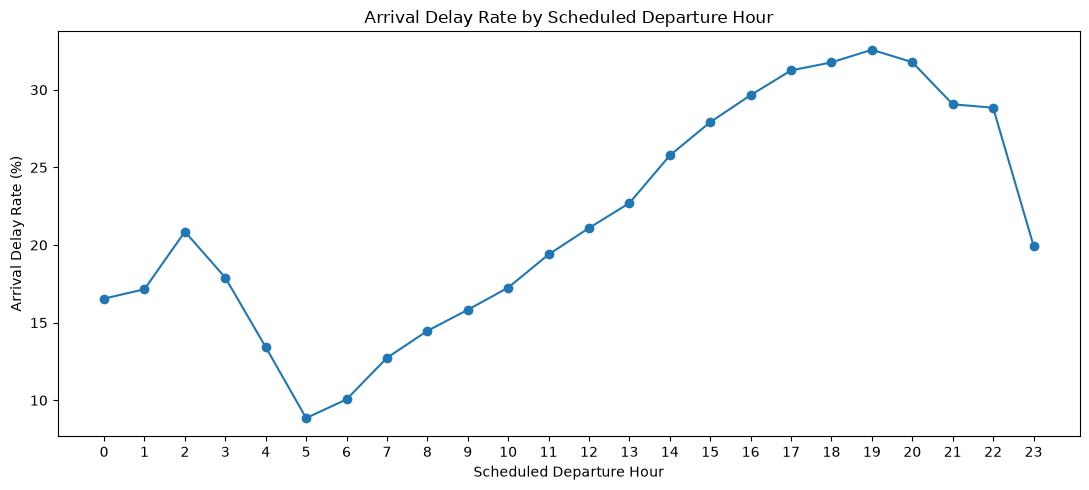

In [11]:
hour_df = (
    pd.concat(hour_parts, ignore_index=True)
    .groupby("ScheduledDepHour", as_index=False)
    .sum(numeric_only=True)
)

hour_df["ArrivalDelayRatePct"] = (
    hour_df["Delayed15Flights"] / hour_df["ValidArrivals"] * 100
)

hour_df = hour_df.sort_values("ScheduledDepHour")

display(hour_df)

plt.figure(figsize=(11, 5))
plt.plot(hour_df["ScheduledDepHour"], hour_df["ArrivalDelayRatePct"], marker="o")
plt.title("Arrival Delay Rate by Scheduled Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Arrival Delay Rate (%)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()


In [12]:
period_df = (
    pd.concat(period_parts, ignore_index=True)
    .groupby("DeparturePeriod", as_index=False)
    .sum(numeric_only=True)
)

period_df["ArrivalDelayRatePct"] = (
    period_df["Delayed15Flights"] / period_df["ValidArrivals"] * 100
)

period_order = ["Night", "Morning", "Afternoon", "Evening"]
period_df["DeparturePeriod"] = pd.Categorical(
    period_df["DeparturePeriod"],
    categories=period_order,
    ordered=True
)
period_df = period_df.sort_values("DeparturePeriod")

display(period_df)


,DeparturePeriod,TotalFlights,ValidArrivals,Delayed15Flights,ArrivalDelayRatePct
3,Night,215288,211729,20112,9.498935
2,Morning,2742560,2704877,400191,14.795164
0,Afternoon,2483073,2438690,644297,26.419799
1,Evening,1560698,1524188,470038,30.838584


In [13]:
day_df = (
    pd.concat(day_parts, ignore_index=True)
    .groupby("DayName", as_index=False)
    .sum(numeric_only=True)
)

day_df["ArrivalDelayRatePct"] = (
    day_df["Delayed15Flights"] / day_df["ValidArrivals"] * 100
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_df["DayName"] = pd.Categorical(
    day_df["DayName"],
    categories=day_order,
    ordered=True
)
day_df = day_df.sort_values("DayName")

display(day_df)


,DayName,TotalFlights,ValidArrivals,Delayed15Flights,ArrivalDelayRatePct
1,Monday,1050150,1031857,245421,23.784400
5,Tuesday,945648,931999,171382,18.388646
6,Wednesday,966102,951705,183569,19.288435
4,Thursday,1040825,1021742,238281,23.321054
0,Friday,1044333,1024839,238296,23.252043
2,Saturday,906399,890640,187061,21.002987
3,Sunday,1048162,1026702,270628,26.358963


In [14]:
weekend_df = (
    pd.concat(weekend_parts, ignore_index=True)
    .groupby("WeekendFlag", as_index=False)
    .sum(numeric_only=True)
)

weekend_df["ArrivalDelayRatePct"] = (
    weekend_df["Delayed15Flights"] / weekend_df["ValidArrivals"] * 100
)

weekend_df["DayType"] = weekend_df["WeekendFlag"].map({
    0: "Weekday",
    1: "Weekend"
})

display(
    weekend_df[
        [
            "DayType",
            "TotalFlights",
            "ValidArrivals",
            "Delayed15Flights",
            "ArrivalDelayRatePct"
        ]
    ]
)


,DayType,TotalFlights,ValidArrivals,Delayed15Flights,ArrivalDelayRatePct
0,Weekday,5047058,4962142,1076949,21.703309
1,Weekend,1954561,1917342,457689,23.871015


## 10. Delay Cause Analysis

In [15]:
cause_df = (
    pd.concat(cause_parts, ignore_index=True)
    .groupby("DelayCause", as_index=False)["DelayMinutes"]
    .sum()
)

total_delay_minutes = cause_df["DelayMinutes"].sum()

cause_df["DelaySharePct"] = (
    cause_df["DelayMinutes"] / total_delay_minutes * 100
)

cause_df = cause_df.sort_values("DelaySharePct", ascending=False)

print(f"Total recorded cause-delay minutes: {total_delay_minutes:,.0f}")
display(cause_df)

top_two_share = cause_df.head(2)["DelaySharePct"].sum()

print(
    f"Top 2 delay causes contribute "
    f"{top_two_share:.2f}% of recorded cause-delay minutes."
)


Total recorded cause-delay minutes: 111,934,625


,DelayCause,DelayMinutes,DelaySharePct
1,Late Aircraft,43862971.0,39.186240
0,Carrier,36326377.0,32.453208
2,NAS,24483761.0,21.873268
4,Weather,7108714.0,6.350773
3,Security,152802.0,0.136510


Top 2 delay causes contribute 71.64% of recorded cause-delay minutes.


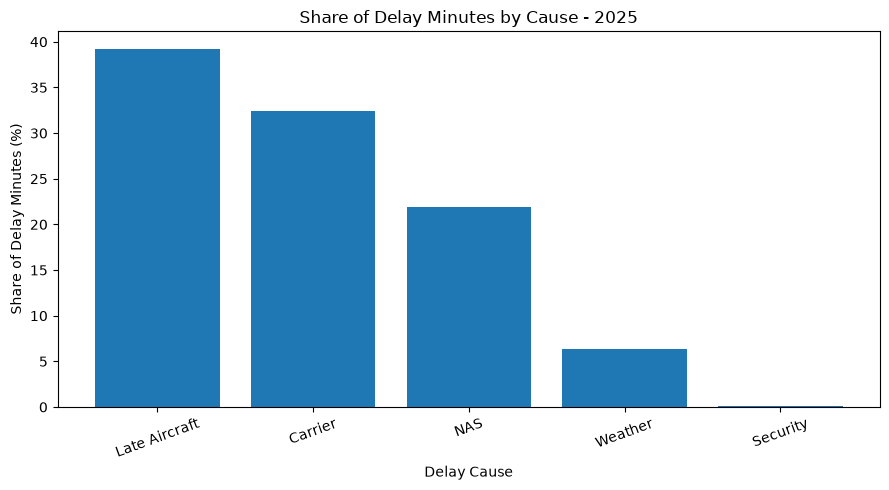

In [16]:
plt.figure(figsize=(9, 5))
plt.bar(cause_df["DelayCause"], cause_df["DelaySharePct"])
plt.title("Share of Delay Minutes by Cause - 2025")
plt.xlabel("Delay Cause")
plt.ylabel("Share of Delay Minutes (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 11. Executive EDA Summary

In [17]:
worst_airline = airline_df.iloc[0]
best_airline = airline_df.iloc[-1]
worst_origin = origin_filtered_df.iloc[0]
worst_destination = destination_filtered_df.iloc[0]
worst_route = route_filtered_df.iloc[0]
worst_hour = hour_df.loc[hour_df["ArrivalDelayRatePct"].idxmax()]
worst_period = period_df.loc[period_df["ArrivalDelayRatePct"].idxmax()]
worst_day = day_df.loc[day_df["ArrivalDelayRatePct"].idxmax()]

print("EXECUTIVE EDA SUMMARY")
print("=" * 70)

print(f"1. Worst month: {worst_month['MonthName']} ({worst_month['ArrivalDelayRatePct']:.2f}%)")
print(f"2. Best month: {best_month['MonthName']} ({best_month['ArrivalDelayRatePct']:.2f}%)")
print(f"3. Highest airline delay rate: {worst_airline['Reporting_Airline']} ({worst_airline['ArrivalDelayRatePct']:.2f}%)")
print(f"4. Lowest airline delay rate: {best_airline['Reporting_Airline']} ({best_airline['ArrivalDelayRatePct']:.2f}%)")
print(f"5. Worst origin airport: {worst_origin['Origin']} ({worst_origin['DepartureDelayRatePct']:.2f}%)")
print(f"6. Worst destination airport: {worst_destination['Dest']} ({worst_destination['ArrivalDelayRatePct']:.2f}%)")
print(f"7. Worst route: {worst_route['Route']} ({worst_route['ArrivalDelayRatePct']:.2f}%)")
print(f"8. Worst departure hour: {int(worst_hour['ScheduledDepHour']):02d}:00 ({worst_hour['ArrivalDelayRatePct']:.2f}%)")
print(f"9. Worst departure period: {worst_period['DeparturePeriod']} ({worst_period['ArrivalDelayRatePct']:.2f}%)")
print(f"10. Worst day: {worst_day['DayName']} ({worst_day['ArrivalDelayRatePct']:.2f}%)")
print(f"11. Largest delay cause: {cause_df.iloc[0]['DelayCause']} ({cause_df.iloc[0]['DelaySharePct']:.2f}%)")


EXECUTIVE EDA SUMMARY
1. Worst month: July (28.89%)
2. Best month: September (16.63%)
3. Highest airline delay rate: F9 (27.91%)
4. Lowest airline delay rate: HA (17.28%)
5. Worst origin airport: SFB (28.72%)
6. Worst destination airport: SFB (36.30%)
7. Worst route: DCA - HPN (39.52%)
8. Worst departure hour: 19:00 (32.58%)
9. Worst departure period: Evening (30.84%)
10. Worst day: Sunday (26.36%)
11. Largest delay cause: Late Aircraft (39.19%)


## 12. Save EDA Tables

In [18]:
monthly_df.to_csv(analysis_path / "monthly_performance_2025.csv", index=False)
airline_df.to_csv(analysis_path / "airline_performance_2025.csv", index=False)
origin_df.to_csv(analysis_path / "origin_airport_performance_2025.csv", index=False)
destination_df.to_csv(analysis_path / "destination_airport_performance_2025.csv", index=False)
route_df.to_csv(analysis_path / "route_performance_2025.csv", index=False)
hour_df.to_csv(analysis_path / "departure_hour_performance_2025.csv", index=False)
period_df.to_csv(analysis_path / "departure_period_performance_2025.csv", index=False)
day_df.to_csv(analysis_path / "day_of_week_performance_2025.csv", index=False)
weekend_df.to_csv(analysis_path / "weekend_performance_2025.csv", index=False)
cause_df.to_csv(analysis_path / "delay_cause_analysis_2025.csv", index=False)

analysis_files = sorted(analysis_path.glob("*.csv"))

print(f"Total analysis files created: {len(analysis_files)}")

for file in analysis_files:
    print(file.name)


Total analysis files created: 10
airline_performance_2025.csv
day_of_week_performance_2025.csv
delay_cause_analysis_2025.csv
departure_hour_performance_2025.csv
departure_period_performance_2025.csv
destination_airport_performance_2025.csv
monthly_performance_2025.csv
origin_airport_performance_2025.csv
route_performance_2025.csv
weekend_performance_2025.csv
